# Setup

In [1]:
import os

import numpy as np
import pandas as pd

import plotly.express as px
import seaborn as sns
import matplotlib
from matplotlib import pyplot as plt

from kneebow.rotor import Rotor
from tqdm.notebook import tqdm, trange

plt.rcParams["figure.dpi"] = 200
sns.set_palette("deep")
sns.set_context("paper")
sns.set_style("whitegrid")

In [2]:
summary = pd.read_csv('/mnt/craig/pan_phylon/bv_brc_files/genome_summary_04_02_26', sep='\t', dtype='object')
metadata = pd.read_csv('/mnt/craig/pan_phylon/bv_brc_files/genome_metadata_04_02_26', sep='\t', dtype='object')

summary.shape

(1059046, 20)

# Filter for species of interest


__ESKAPEEs:__
- _Enterococcus faecium_
- _Staphylococcus aureus_
- _Klebsiella pneumoniae_
- _Acinetobacter baumannii_
- _Pseudomonas aeruginosa_
- _Enterobacter spp_ (genus-level analysis)
- _Escherichia coli_ (including _Shigella_)


__Other pathogens of interest:__
- _Pseudomonas putida_
- _Pseudomonas syringae_
- _Mycobacterium tuberculosis_
- _Salmonella_ (genus-level analysis)


__Other species:__
- _Bacillus subtilis_
- _Streptococcus pyogenes_

In [3]:
def filter_by_species(summary, SPECIES_NAME):
    species_summary = summary[summary["genome_name"].str.contains(SPECIES_NAME)] # Filter for only SPECIES_NAME strains 
    species_summary = species_summary.dropna(subset=['genome_length']) # must have reported genome_length
    species_summary = species_summary.dropna(subset=['patric_cds']) # must have reported patric_cds
    
    # Ensure genome_length and patric_cds are ints
    species_summary['genome_length'] = species_summary.genome_length.astype('int')
    species_summary['patric_cds'] = species_summary.patric_cds.astype('int')

    return species_summary


def filter_by_genome_quality(
    species_summary,
    min_thresh_n50=None,
    max_contig=None,
    contamination_cutoff=None,
    completeness_cutoff=None,
    return_stats=True,
):
    
    # Split genomes into "Complete" & "WGS" bins
    species_complete_summary = species_summary[species_summary.genome_status == 'Complete']
    species_wgs_summary = species_summary[species_summary.genome_status == 'WGS']

    # internal function (for filtration)
    def get_length():
        return species_complete_summary.shape[0] + species_wgs_summary.shape[0]
    
    # Record initial lengths (for filtration statistics)
    filtration_metrics_list = ['prefiltration', 'L50/N50', 'contig_count', 'CheckM_completeness_contamination']
    filtration_columns = ['initial', 'num_filtered', 'remaining']
    df_filtration = pd.DataFrame(index=filtration_metrics_list, columns=filtration_columns)
    
    df_filtration.loc['prefiltration', 'initial'] = species_summary.shape[0]
    df_filtration.loc['prefiltration', 'remaining'] = df_filtration.loc['prefiltration', 'initial']
    df_filtration.loc['prefiltration', 'num_filtered'] = \
        df_filtration.loc['prefiltration', 'initial'] \
        - df_filtration.loc['prefiltration', 'remaining']
    
    # Filter complete sequences by L50 & N50 score metrics
    species_complete_summary = _filter_l50(species_complete_summary)
    species_complete_summary = _filter_n50(species_complete_summary, min_thresh_n50)
    
    # Record L50 & N50 filration metrics
    df_filtration.loc['L50/N50', 'initial'] = df_filtration.loc['prefiltration', 'remaining']
    df_filtration.loc['L50/N50', 'remaining'] = species_complete_summary.shape[0] + species_wgs_summary.shape[0]
    df_filtration.loc['L50/N50', 'num_filtered'] = \
        df_filtration.loc['L50/N50', 'initial'] \
        - df_filtration.loc['L50/N50', 'remaining']
    
    # Filter other WGS sequences by contig count
    species_wgs_summary = _filter_by_contig(species_wgs_summary, max_contig)
    
    # Record contig count filtration metrics
    df_filtration.loc['contig_count', 'initial'] = df_filtration.loc['L50/N50', 'remaining']
    df_filtration.loc['contig_count', 'remaining'] = species_complete_summary.shape[0] + species_wgs_summary.shape[0]
    df_filtration.loc['contig_count', 'num_filtered'] = \
        df_filtration.loc['contig_count', 'initial'] \
        - df_filtration.loc['contig_count', 'remaining']
    
    # Further filter other WGS sequences by CheckM contamination & completeness score metrics
    species_wgs_summary = _filter_checkM_contamination(species_wgs_summary, contamination_cutoff)
    species_wgs_summary = _filter_checkM_completeness(species_wgs_summary, completeness_cutoff)

    df_filtration.loc['CheckM_completeness_contamination', 'initial'] = df_filtration.loc['contig_count', 'remaining']
    df_filtration.loc['CheckM_completeness_contamination', 'remaining'] = species_complete_summary.shape[0] + species_wgs_summary.shape[0]
    df_filtration.loc['CheckM_completeness_contamination', 'num_filtered'] = \
        df_filtration.loc['CheckM_completeness_contamination', 'initial'] \
        - df_filtration.loc['CheckM_completeness_contamination', 'remaining']
    
    # Merge complete sequences and WGS sequences metadata
    filtered_species_summary = pd.concat([species_complete_summary, species_wgs_summary])

    # Typecase relevant columns as numeric
    filtered_species_summary['contig_l50'] = filtered_species_summary['contig_l50'].astype('int')
    filtered_species_summary['contig_n50'] = filtered_species_summary['contig_l50'].astype('int')
    filtered_species_summary['contigs'] = filtered_species_summary['contigs'].astype('int')
    filtered_species_summary['checkm_contamination'] = filtered_species_summary['checkm_contamination'].astype('float')
    filtered_species_summary['checkm_completeness'] = filtered_species_summary['checkm_completeness'].astype('float')

    filtered_species_summary['gc_content'] = filtered_species_summary['gc_content'].astype('float')
    
    if return_stats:
        return filtered_species_summary, df_filtration
    else:
        return filtered_species_summary
    
# Individual filtration functions

def _filter_l50(species_complete_summary, l50_score=1):
    species_complete_summary = species_complete_summary.dropna(subset=['contig_l50']) # must have reported L50 score
    species_complete_summary['contig_l50'] = species_complete_summary['contig_l50'].astype('int') # typecase to numeric
    
    good_l50 = species_complete_summary.contig_l50 == l50_score # Must be 1 for (most) bacterial complete seqs
    species_complete_summary = species_complete_summary[good_l50]

    return species_complete_summary


def _filter_n50(species_complete_summary, min_thresh_n50):
    species_complete_summary = species_complete_summary.dropna(subset=['contig_n50']) # must have reported N50 score
    species_complete_summary['contig_n50'] = species_complete_summary['contig_n50'].astype('int') # typecase to numeric
    
    if min_thresh_n50:
        cond = species_complete_summary.contig_n50 > min_thresh_n50
        species_complete_summary = species_complete_summary[cond]
    
    return species_complete_summary


def _filter_by_contig(species_wgs_summary, max_contig):
    species_wgs_summary = species_wgs_summary.dropna(subset=['contigs']) # must have reported contig count
    species_wgs_summary['contigs'] = species_wgs_summary['contigs'].astype('int') # typecase to numeric
    
    if max_contig:
        species_wgs_summary = species_wgs_summary[species_wgs_summary.contig <= max_contig]
    else:
        species_wgs_summary = _remove_contig_outliers(species_wgs_summary)

    return species_wgs_summary


def _filter_checkM_contamination(species_wgs_summary, contamination_cutoff):
    species_wgs_summary = species_wgs_summary.dropna(subset=['checkm_contamination']) # must have reported Contamination score
    species_wgs_summary.loc[:,'checkm_contamination'] = species_wgs_summary['checkm_contamination'].astype('float') # typecase to numeric
    
    if contamination_cutoff:
        cond = species_wgs_summary.checkm_contamination < contamination_cutoff
    else:
        kneebow_cutoff = _get_kneebow_cutoff(species_wgs_summary, column='checkm_contamination', curve='elbow')
        cond = species_wgs_summary.checkm_contamination < kneebow_cutoff
    
    species_wgs_summary = species_wgs_summary[cond]
    
    return species_wgs_summary


def _filter_checkM_completeness(species_wgs_summary, completeness_cutoff):
    species_wgs_summary = species_wgs_summary.dropna(subset=['checkm_completeness']) # must have reported Completeness score
    species_wgs_summary['checkm_completeness'] = species_wgs_summary['checkm_completeness'].astype('float') # typecase to numeric
    
    if completeness_cutoff:
        cond = species_wgs_summary.checkm_completeness > completeness_cutoff
    else:
        kneebow_cutoff = _get_kneebow_cutoff(species_wgs_summary, column='checkm_completeness', curve='knee')
        cond = species_wgs_summary.checkm_completeness > kneebow_cutoff
    
    species_wgs_summary = species_wgs_summary[cond]
    
    return species_wgs_summary

# Helper functions

def _remove_contig_outliers(species_wgs_summary):
    df = species_wgs_summary.copy()
    
    # Step 1: Calculate the IQR
    Q1 = df['contigs'].quantile(0.25)
    Q3 = df['contigs'].quantile(0.75)
    IQR = Q3 - Q1
    
    # Step 2: Find the upper fence
    upper_fence = Q3 + 1.5 * IQR

    # Step 3: Remove all entries above upper fence limit (clear outliers)
    outlier_cond = species_wgs_summary.contigs <= upper_fence
    species_wgs_summary = species_wgs_summary[outlier_cond]
    
    # Step 4: Remove all entries > 2.5 * median of remaining values
    upper_limit_median = 2.5 * species_wgs_summary.contigs.median()
    outlier_cond2 = species_wgs_summary.contigs <= upper_limit_median
    species_wgs_summary = species_wgs_summary[outlier_cond2]
    
    return species_wgs_summary


def _get_kneebow_cutoff(species_wgs_summary, column, curve):
    df = species_wgs_summary.copy()

    if curve.lower() == 'elbow':
        df = df.sort_values(by=column, ascending=True)
    elif curve.lower() == 'knee':
        df = df.sort_values(by=column, ascending=False)
    else:
        raise ValueError(f'column must be either "elbow" or "knee". {column} was provided instead.')
    
    # set strain index according to ascending/descending values (depending on knee or elbow)
    df = df.reset_index()
    
    # transform input into form necessary for kneebow package
    results_itr = zip(list(df.index), list(df[column]))
    data = list(results_itr)
    
    rotor = Rotor()
    rotor.fit_rotate(data)
    
    if curve.lower() == 'elbow':
        elbow_idx = rotor.get_elbow_index()
        kneebow_cutoff = df[column][elbow_idx]
    elif curve.lower() == 'knee':
        knee_idx = rotor.get_knee_index()
        kneebow_cutoff = df[column][knee_idx]
    
    return kneebow_cutoff



## _Staphylococcus aureus_

In [4]:
SPECIES_NAME = 'Streptococcus pyogenes' # Just writing the genus name also works

In [5]:
summary.genome_name.str.contains(SPECIES_NAME).sum()

2432

In [6]:
# How many strains of the species/genus are available
species_summary = filter_by_species(summary, SPECIES_NAME)

display(
    species_summary.shape,
    species_summary.head()
)

(2432, 20)

,genome_id,genome_name,taxon_id,genome_status,genome_length,gc_content,contig_l50,contig_n50,chromosomes,plasmids,contigs,patric_cds,refseq_cds,trna,rrnacoarse_consistency,fine_consistency,checkm_completeness,checkm_contamination,genome_qualitydate_created,date_modified
817571,1314.547,Streptococcus pyogenes,1314,Plasmid,19203,34.39,NaN,NaN,NaN,1,1,25,21,NaN,NaN,NaN,NaN,NaN,NaN,2017-12-30T07:25:44.857Z
817572,1314.540,Streptococcus pyogenes,1314,Plasmid,28975,34.76,NaN,NaN,NaN,1,1,38,35,NaN,NaN,NaN,NaN,NaN,NaN,2017-12-29T17:49:02.717Z
817573,1210041.3,Streptococcus pyogenes 06BA18369,1210041,WGS,1813404,38.4,9,71565,0,0,47,1825,0,30,NaN,99.0,100.0,0.0,NaN,2015-03-16T03:17:09.594Z
817574,1314.4070,Streptococcus pyogenes 1004,1314,Complete,1842099,38.30196,1,1842099,1,0,1,1798,1706,67,NaN,99.9,100.0,0.0,NaN,2023-04-21T00:08:53.590Z
817575,1314.4068,Streptococcus pyogenes 1039,1314,Complete,1856557,38.30591,1,1856557,1,0,1,1827,1734,67,NaN,99.8,100.0,0.0,NaN,2023-04-21T00:00:24.086Z


## Initial Plot (unfiltered data)

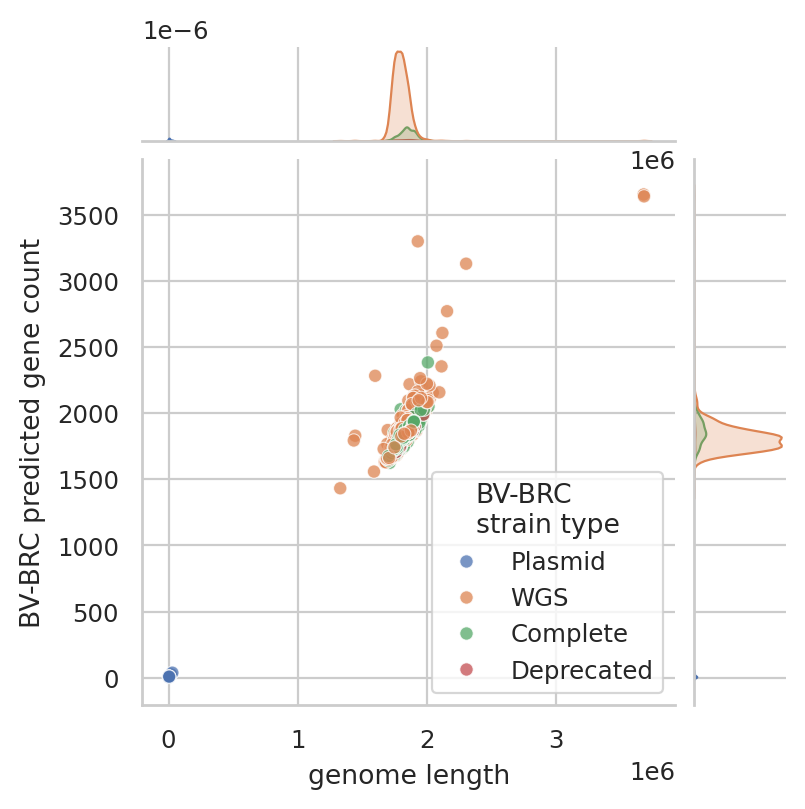

In [7]:
# Initial unfiltered strain plot
h = sns.jointplot(
    data=species_summary,
    x="genome_length",
    y="patric_cds",
    hue="genome_status",
    alpha=0.75,
    height=4
)

h.ax_joint.legend(
    title='BV-BRC\nstrain type',
)

h.ax_joint.set_xlabel("genome length")
h.ax_joint.set_ylabel("BV-BRC predicted gene count")
plt.show()

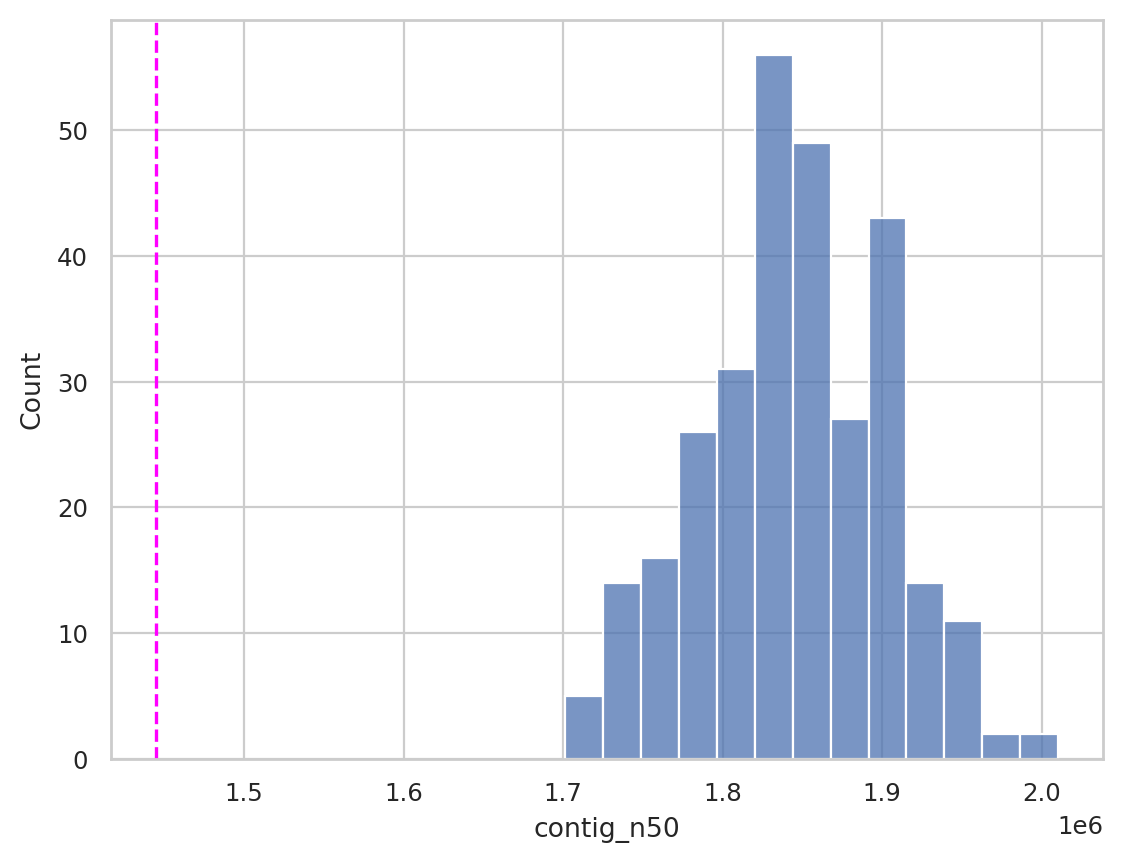

In [8]:
# Find reference strain N50 value from NCBI Genome and multiply by 0.85
# If your species/genus has multiple reference strains, pick the smallest by genome length
# If you are still confused, just send Sidd an email

# Only applies for Complete sequences
species_complete_summary = species_summary[species_summary.genome_status == 'Complete']

fig, ax = plt.subplots()

# 5.3 Mb is the referene N50 value for this species https://www.ncbi.nlm.nih.gov/datasets/genome/GCF_000013425.1/)
species_ref_n50 = 1.7e6
min_thresh_n50 = int(0.85 * species_ref_n50)

# Most Complete sequences pass this threshold
sns.histplot(species_complete_summary.contig_n50.dropna().astype('int'), ax=ax)
plt.axvline(x=min_thresh_n50, color='#ff00ff', linestyle='--')

## Initial Filtration Report

In [9]:
filtered_species_summary, df_filtration = filter_by_genome_quality(
    species_summary,
    min_thresh_n50=min_thresh_n50,
    max_contig=None,
    contamination_cutoff=None,
    completeness_cutoff=None,
    return_stats=True,
)

display(
    f'Filtered Strains:',
    filtered_species_summary.shape,
    f'------------------------------',
    f'Filtration Report',
    df_filtration
)

'Filtered Strains:'

(627, 20)

'------------------------------'

'Filtration Report'

,initial,num_filtered,remaining
prefiltration,2432,0,2432
L50/N50,2432,58,2374
contig_count,2374,164,2210
CheckM_completeness_contamination,2210,1583,627


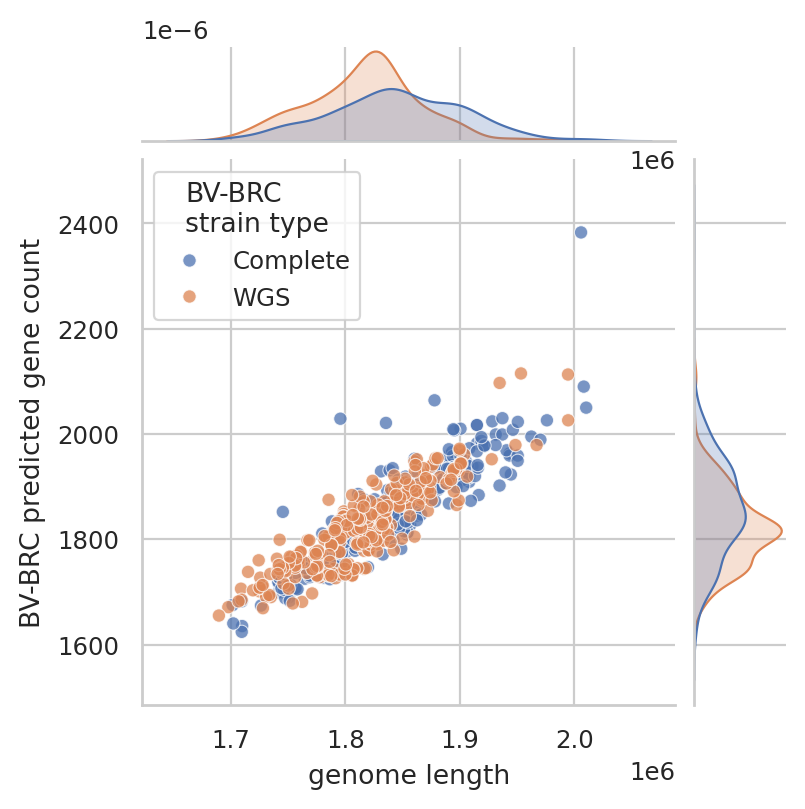

In [10]:
# Same initial plot but with only (first-pass) filtered strains
# For this plot, make sure your WGS sequences form a nice line
# Complete sequences may be all over the place

# For this example, 3.2Mb looks like a good cutoff to for max genome length
# and 10k looks like a good cutoff to for max predicted genes (though we could go lower)

h = sns.jointplot(
    data=filtered_species_summary,
    x="genome_length",
    y="patric_cds",
    hue="genome_status",
    alpha=0.75,
    height=4
)

h.ax_joint.legend(
 title='BV-BRC\nstrain type'
)

h.ax_joint.set_xlabel("genome length")
h.ax_joint.set_ylabel("BV-BRC predicted gene count")
plt.show()

# (Optional) Filter by genome length and predicted cds count

## Filter by genome length

In [11]:
# This step is optional (only needed if you are filtering more strains)
max_genome_length = 2.5e6
max_predicted_cds = 2.2e3

# Step 1: Filter strains by min genome length
cond = filtered_species_summary['genome_length'] < max_genome_length
filtered_species_summary = filtered_species_summary[cond]

# Step 2: Calculate min genome length statistics and add to df_filtration
df_temp = pd.DataFrame(index=['max_genome_length'], columns=df_filtration.columns)

df_temp.loc['max_genome_length', 'initial'] = df_filtration.loc['CheckM_completeness_contamination', 'remaining']
df_temp.loc['max_genome_length', 'remaining'] = filtered_species_summary.shape[0]
df_temp.loc['max_genome_length', 'num_filtered'] = \
    df_temp.loc['max_genome_length', 'initial'] \
    - df_temp.loc['max_genome_length', 'remaining']

df_filtration = pd.concat([df_filtration, df_temp])

# Step 3: Filter strains by max predicted cds
cond = filtered_species_summary['patric_cds'] < max_predicted_cds
filtered_species_summary = filtered_species_summary[cond]

# Step 4: Calculate max genome length statistics and add to df_filtration
df_temp = pd.DataFrame(index=['max_predicted_cds'], columns=df_filtration.columns)

df_temp.loc['max_predicted_cds', 'initial'] = df_filtration.loc['max_genome_length', 'remaining']
df_temp.loc['max_predicted_cds', 'remaining'] = filtered_species_summary.shape[0]
df_temp.loc['max_predicted_cds', 'num_filtered'] = \
    df_temp.loc['max_predicted_cds', 'initial'] \
    - df_temp.loc['max_predicted_cds', 'remaining']

df_filtration = pd.concat([df_filtration, df_temp])

df_filtration

,initial,num_filtered,remaining
prefiltration,2432,0,2432
L50/N50,2432,58,2374
contig_count,2374,164,2210
CheckM_completeness_contamination,2210,1583,627
max_genome_length,627,0,627
max_predicted_cds,627,1,626


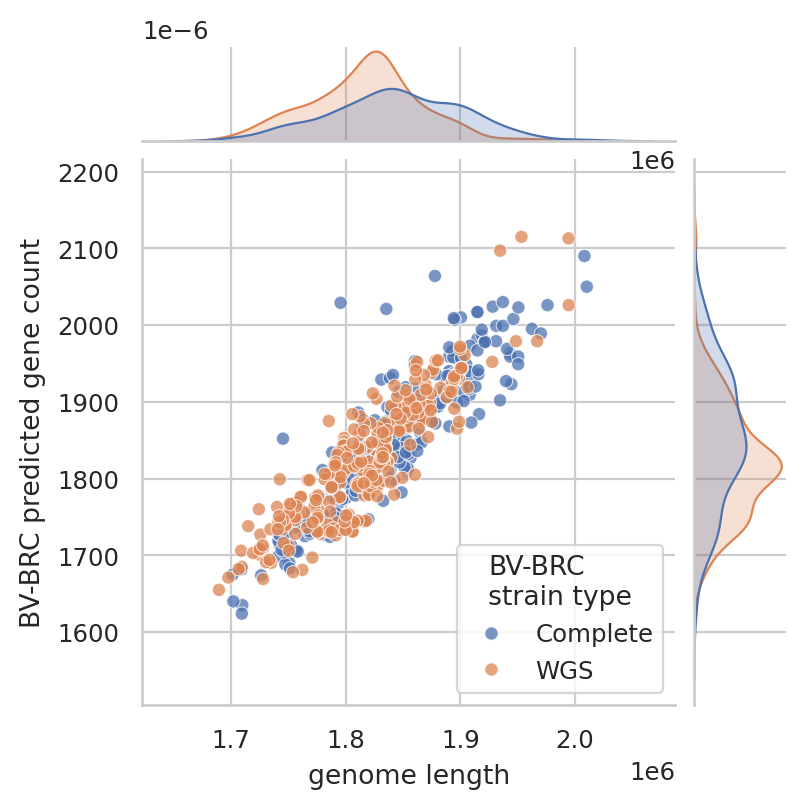

In [12]:
# Second look at filtered plot
h = sns.jointplot(
    data=filtered_species_summary,
    x="genome_length",
    y="patric_cds",
    hue="genome_status",
    alpha=0.75,
    height=4
)

h.ax_joint.legend(
 title='BV-BRC\nstrain type'
)

h.ax_joint.set_xlabel("genome length")
h.ax_joint.set_ylabel("BV-BRC predicted gene count")
plt.show()

# (Optional) Filter by GC content

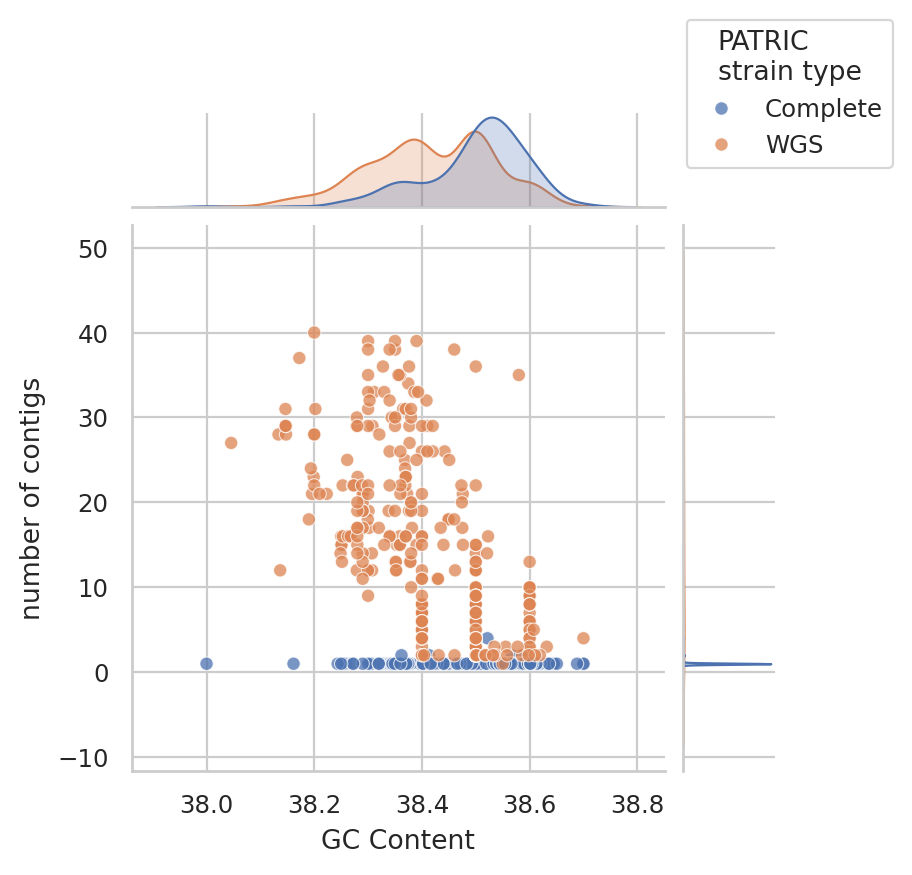

In [13]:
# Ensure GC content makes sense
# Remove any big outliers (in this case, anything > 35)

h = sns.jointplot(
    data=filtered_species_summary,
    x="gc_content",
    y="contigs",
    hue="genome_status",
    alpha=0.75,
    height=4
)

h.ax_joint.legend(
    title='PATRIC\nstrain type',
    bbox_to_anchor=(1.45,1.4)
)

h.ax_joint.set_xlabel("GC Content")
h.ax_joint.set_ylabel("number of contigs")
plt.show()

In [14]:
# This step is optional (only needed if you are filtering more strains)
gc_content_min = 30
gc_content_max = 40

# Step 1: Filter strains by gc_content
cond1 = filtered_species_summary['gc_content'] > gc_content_min
cond2 = filtered_species_summary['gc_content'] < gc_content_max
filtered_species_summary = filtered_species_summary[cond1 & cond2]

# Step 2: Calculate min genome length statistics and add to df_filtration
df_temp = pd.DataFrame(index=['gc_content'], columns=df_filtration.columns)

df_temp.loc['gc_content', 'initial'] = df_filtration.loc['max_predicted_cds', 'remaining']
df_temp.loc['gc_content', 'remaining'] = filtered_species_summary.shape[0]
df_temp.loc['gc_content', 'num_filtered'] = \
    df_temp.loc['gc_content', 'initial'] \
    - df_temp.loc['gc_content', 'remaining']

df_filtration = pd.concat([df_filtration, df_temp])

df_filtration

,initial,num_filtered,remaining
prefiltration,2432,0,2432
L50/N50,2432,58,2374
contig_count,2374,164,2210
CheckM_completeness_contamination,2210,1583,627
max_genome_length,627,0,627
max_predicted_cds,627,1,626
gc_content,626,0,626


In [15]:
# Num of (first-pass) filtered strains (for NMF)
cond = filtered_species_summary.genome_status == 'Complete'
filtered_species_summary[cond].shape[0]

282

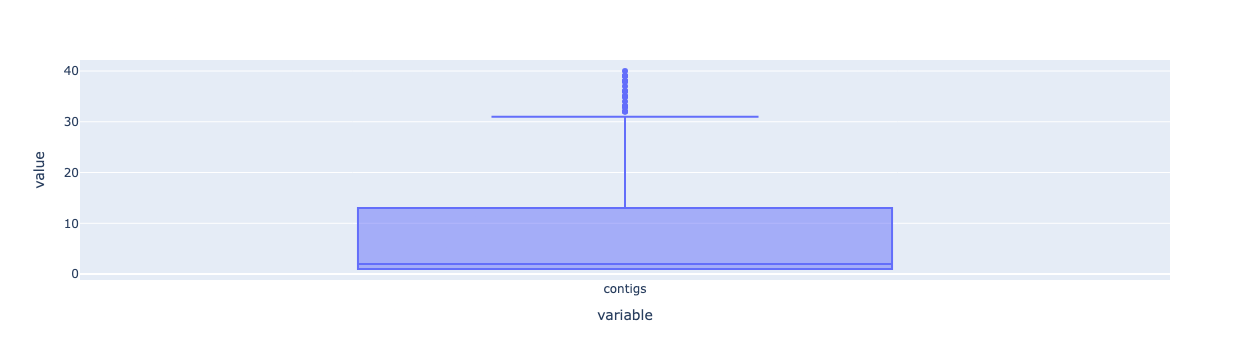

In [16]:
# Make sure contig distribution looks good (little to no outliers)
# For this example, it looks okay (only 11 outliers with all of them being close to the upper fence)
px.box(filtered_species_summary.contigs)

In [17]:
filtered_species_summary = _remove_contig_outliers(filtered_species_summary)

# Step 2: Calculate min genome length statistics and add to df_filtration
df_temp = pd.DataFrame(index=['contig_outliers'], columns=df_filtration.columns)

df_temp.loc['contig_outliers', 'initial'] = df_filtration.loc['gc_content', 'remaining']
df_temp.loc['contig_outliers', 'remaining'] = filtered_species_summary.shape[0]
df_temp.loc['contig_outliers', 'num_filtered'] = \
    df_temp.loc['contig_outliers', 'initial'] \
    - df_temp.loc['contig_outliers', 'remaining']

df_filtration = pd.concat([df_filtration, df_temp])

df_filtration

,initial,num_filtered,remaining
prefiltration,2432,0,2432
L50/N50,2432,58,2374
contig_count,2374,164,2210
CheckM_completeness_contamination,2210,1583,627
max_genome_length,627,0,627
max_predicted_cds,627,1,626
gc_content,626,0,626
contig_outliers,626,254,372


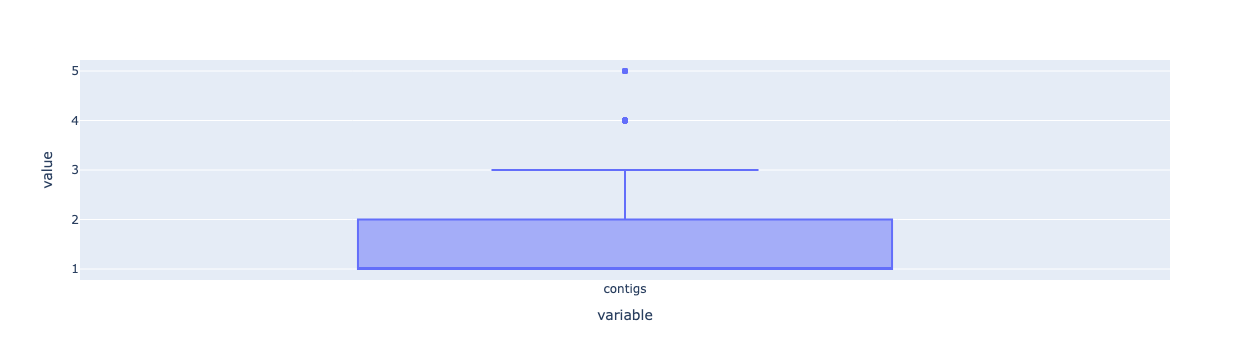

In [18]:
# Replotting shows the upper fence is now at 95 instead of 110. IQR is minimally unaffected
px.box(filtered_species_summary.contigs)

In [19]:
import plotly.graph_objects as go
import pandas as pd
import plotly.express as px
import pandas.api.types

def create_funnel_plot(df, title="Data Filtration Funnel", colorscheme=None, text_font_size=14, title_font_size=None):
    """
    Create a Plotly funnel area plot showing data filtration stages with stage names, raw values, and percentages.

    Parameters
    ----------
    df : pandas.DataFrame
        Input DataFrame containing filtration stages with a 'remaining' column
        showing the number of items remaining at each stage. Stage names should be
        in the index or a 'stage' column.
    title : str, optional
        Title of the plot. Default is "Data Filtration Funnel".
    colorscheme : str or list, optional
        Custom color scheme to use for the funnel segments. Can be a Plotly Express
        qualitative color sequence name (e.g., 'Alphabet') or a list of color strings.
        Defaults to px.colors.qualitative.Plotly if None.
    text_font_size : int, optional
        Font size for the text in the funnel plot. Default is 14.
    title_font_size : int, optional
        Font size for the title of the plot. If None, defaults to text_font_size + 4.

    Returns
    -------
    plotly.graph_objects.Figure
        A Plotly figure object containing the funnel area plot.

    Examples
    --------
    >>> df = pd.DataFrame({'remaining': [23919, 22430, 20528, 19179, 19178, 19086, 19084, 18828]},
    ...                   index=['prefiltration', 'L50/N50', 'contig_count', 'CheckM_completeness_contamination',
    ...                          'max_genome_length', 'max_predicted_cds', 'gc_content', 'contig_outliers'])
    >>> fig = create_funnel_plot(df, colorscheme='Alphabet', text_font_size=14, title_font_size=18)
    >>> fig.show()
    """
    # Ensure the DataFrame has stage names (try index first, then look for a 'stage' column)
    if 'stage' in df.columns:
        stages = df['stage']
    elif not pandas.api.types.is_any_real_numeric_dtype(df.index):
        # Use the index as stage names if it's not numeric (e.g., strings like 'prefiltration')
        stages = df.index
    else:
        raise ValueError("DataFrame must have stage names either in the index (non-numeric) or a 'stage' column.")

    # Get the initial prefiltration value for percentage calculation
    total_initial = df['remaining'].iloc[0]
    
    # Calculate custom percentages relative to the initial value
    custom_percentages = [100 * (val / total_initial) for val in df['remaining']]
    
    # Format custom text with stage name, value, and percentage
    custom_text = [f"{stage}<br>{val}<br>{pct:.1f}%" 
                   for stage, val, pct in zip(stages, df['remaining'], custom_percentages)]
    
    # Determine the color scheme
    if colorscheme is None:
        colors = px.colors.qualitative.Plotly
    elif isinstance(colorscheme, str):
        # Try to use a Plotly Express qualitative color sequence
        try:
            colors = getattr(px.colors.qualitative, colorscheme)
        except AttributeError:
            raise ValueError(f"Unknown Plotly Express color scheme: {colorscheme}. Use a valid qualitative color sequence name like 'Alphabet'.")
    else:
        # Assume colorscheme is a list of color strings
        colors = colorscheme
    
    # Ensure we have enough colors by cycling if necessary
    if len(colors) < len(df):
        colors = colors * (len(df) // len(colors) + 1)
    colors = colors[:len(df)]
    
    # Set title font size (default to text_font_size + 4 if not specified)
    if title_font_size is None:
        title_font_size = text_font_size + 4
    
    # Create the funnel area plot
    fig = go.Figure(go.Funnelarea(
        text=custom_text,  # Use custom text with stage names, values, and percentages
        values=df['remaining'],
        title={'text': title, 'font': {'size': title_font_size}},  # Set title font size
        textinfo="text",  # Use the custom text we provided
        showlegend=False,  # Remove the legend
        textfont=dict(size=text_font_size)  # Set uniform font size for all text
    ))
    
    # Update traces to use custom colors
    fig.update_traces(marker={'colors': colors})
    
    # Update layout for better visualization
    fig.update_layout(
        width=800,
        height=800,
        funnelmode="stack"
    )
    
    return fig

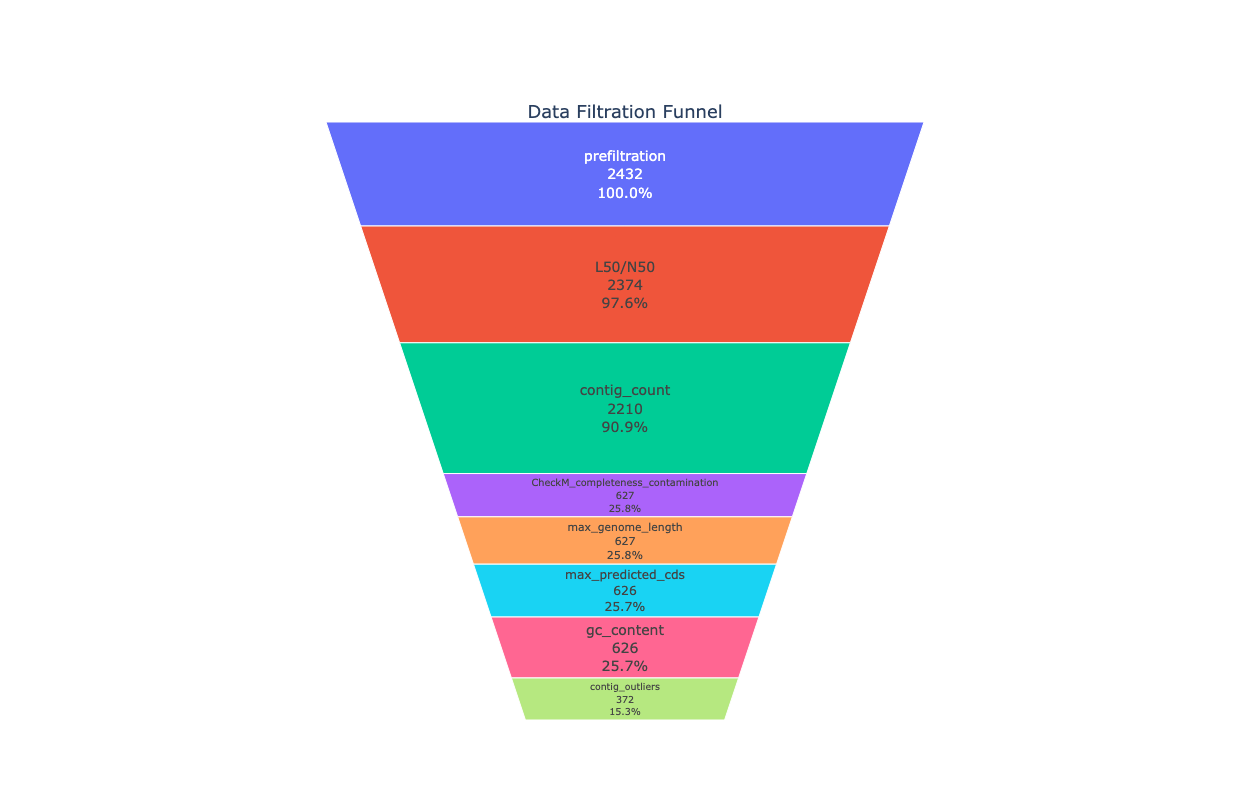

In [20]:
fig = create_funnel_plot(df_filtration)
fig.show()

In [21]:
fig.write_image("funnel_plot.pdf")

/tmp/ipykernel_2813766/2926567182.py:1: DeprecationWarning:


Support for Kaleido versions less than 1.0.0 is deprecated and will be removed after September 2025.
Please upgrade Kaleido to version 1.0.0 or greater (`pip install 'kaleido>=1.0.0'` or `pip install 'plotly[kaleido]'`).




# Save (first-pass) filtered Genome Summary & Genome Metadata Files

In [22]:
PAN_PHYLON_DIR = '/mnt/craig/pan_phylon'
NUM_WORDS = len(SPECIES_NAME.split(' '))

filepath = None
if NUM_WORDS > 1: # Most species
    filepath = os.path.join(PAN_PHYLON_DIR, SPECIES_NAME.split(' ')[0][0] + '_' + SPECIES_NAME.split(' ')[1])
elif NUM_WORDS == 1: # In case you are doing genus-level analysis
    filepath = os.path.join(PAN_PHYLON_DIR, SPECIES_NAME)
else:
    raise ValueError(f'SPECIES_NAME is must contain 1 word (for genus) or 2 (for species). {NUM_WORDS} words found instead.')

filepath = os.path.join(filepath, 'metadata')
filepath = os.path.join(filepath, 'filtered_species_summary.csv')
filtered_species_summary.to_csv(filepath)

In [23]:
filtered_species_metadata = metadata.loc[filtered_species_summary.index]

filepath = os.path.join(filepath.split('filtered_species_summary.csv')[0], 'filtered_species_metadata.csv')
filtered_species_metadata.to_csv(filepath)